Эпизод 1

In [1]:
import sympy as sp

lam, mu, rho = sp.symbols('lambda mu rho')

M = sp.Matrix([
    [0, 0, 0, -1/rho, 0, 0, 0, 0, 0],
    [0, 0, 0, 0, -1/rho, 0, 0, 0, 0],
    [0, 0, 0, 0, 0, -1/rho, 0, 0, 0],
    [-(lam + 2*mu), 0, 0, 0, 0, 0, 0, 0, 0],
    [0, -mu, 0, 0, 0, 0, 0, 0, 0],
    [0, 0, -mu, 0, 0, 0, 0, 0, 0],
    [-lam, 0, 0, 0, 0, 0, 0, 0, 0],
    [0, 0, 0, 0, 0, 0, 0, 0, 0],
    [-lam, 0, 0, 0, 0, 0, 0, 0, 0]
])

eigenvalues = M.eigenvals()

print("Собственные значения и их кратности:")
for val, mult in eigenvalues.items():
    print(f"Собственное значение: {val}, Кратность: {mult}")

Собственные значения и их кратности:
Собственное значение: -sqrt((lambda + 2*mu)/rho), Кратность: 1
Собственное значение: sqrt((lambda + 2*mu)/rho), Кратность: 1
Собственное значение: -sqrt(mu/rho), Кратность: 2
Собственное значение: sqrt(mu/rho), Кратность: 2
Собственное значение: 0, Кратность: 3


Эпизод 2

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path


def read_system(path):
    with open(path, encoding="utf-8") as f:
        lines = [line.strip() for line in f if line.strip()]
    n = int(lines[0])
    A = np.array([list(map(float, lines[i].split())) for i in range(1, n + 1)])
    b = np.array(list(map(float, lines[n + 1].split())))
    return A, b, n


def solve_and_save(path, out_png):
    A, b, n = read_system(path)
    x = np.linalg.solve(A, b)
    print(f"--- {path} (N={n}) ---")
    print("x =", x)
    print("residual =", np.linalg.norm(A @ x - b))
    print()

    plt.figure(figsize=(14, 6))
    plt.bar(np.arange(n), x, width=0.8, color="steelblue")
    plt.grid(True, zorder=0)
    plt.xticks(np.arange(0, n, max(1, n // 20)))
    plt.xlabel("i")
    plt.ylabel("x[i]")
    plt.title(f"x для {Path(path).name} (N={n})")
    plt.tight_layout()
    plt.savefig(out_png, dpi=150)
    plt.close()
    print(f"Сохранено: {out_png}\n")


solve_and_save("TestMatrix.txt", "test_plot.png")
solve_and_save("RealMatrix.txt", "real_plot.png")

--- TestMatrix.txt (N=3) ---
x = [ 2. -2.  9.]
residual = 0.0

Сохранено: test_plot.png

--- RealMatrix.txt (N=100) ---
x = [ 374.99999999  524.          671.          816.00000001  958.99999999
 1100.         1239.         1375.99999999 1511.         1644.
 1775.         1904.         2030.99999999 2156.00000001 2279.00000001
 2400.00000001 2519.         2636.00000001 2750.99999999 2863.99999999
 2975.         3084.         3191.         3296.00000001 3398.99999999
 3499.99999999 3599.         3696.         3790.99999998 3884.
 3974.99999999 4064.         4151.00000001 4236.00000001 4319.
 4399.99999999 4479.         4555.99999999 4630.99999999 4703.99999999
 4775.00000001 4844.         4911.         4975.99999999 5039.00000001
 5100.         5159.00000001 5216.         5271.         5323.99999999
 5375.         5424.00000001 5471.         5515.99999999 5559.
 5600.00000001 5639.00000001 5676.         5711.         5744.00000001
 5775.00000002 5803.99999999 5831.         5856.        

![alt text](test_plot-1.png)
![alt text](real_plot-1.png)

Эпизод 3

Eq(y(x), sqrt(2)*exp(-2*x))


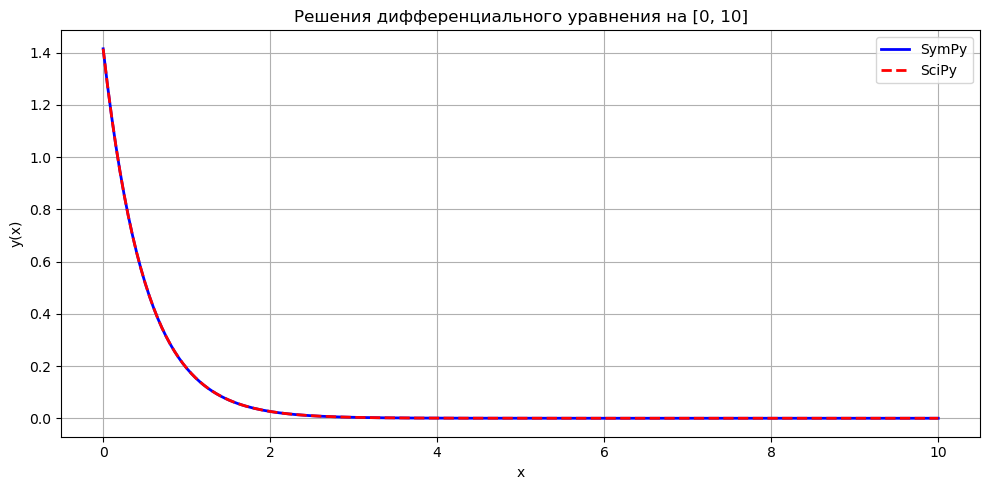

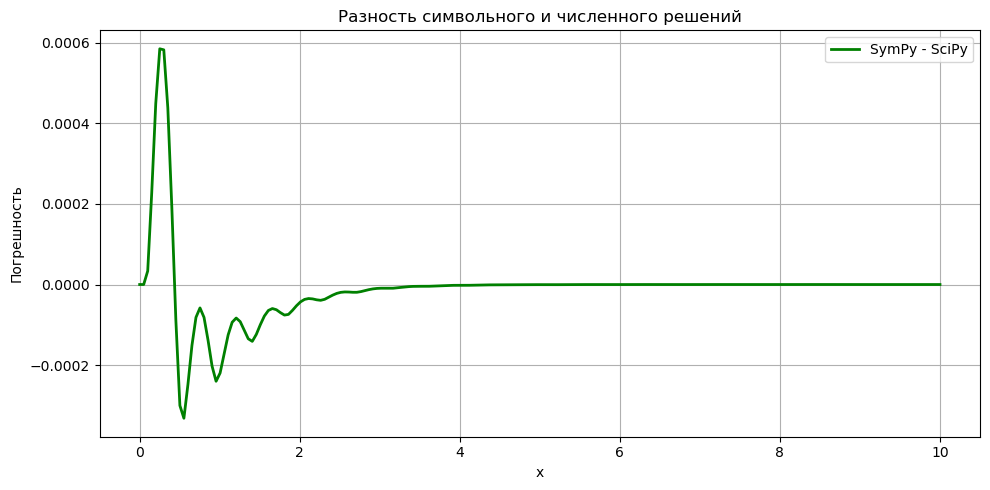

In [ ]:
import sympy as sp
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

x = sp.symbols('x')
y = sp.Function('y')
diffeq = sp.Eq(y(x).diff(x), -2 * y(x))
sol_sym = sp.dsolve(diffeq, y(x), ics={y(0): sp.sqrt(2)})
print(sol_sym)

y_sym_func = sp.lambdify(x, sol_sym.rhs, modules=['numpy'])

def ode_system(x, y):
    return -2 * y

x_span = (0, 10)
x_eval = np.linspace(0, 10, 200)
y0 = [np.sqrt(2)]

sol_num = solve_ivp(ode_system, x_span, y0, t_eval=x_eval, method='RK45')
y_num_func = sol_num.y[0]

plt.figure(figsize=(10, 5))
plt.plot(x_eval, y_sym_func(x_eval), label='SymPy', color='blue', linewidth=2)
plt.plot(x_eval, y_num_func, label='SciPy', color='red', linestyle='--', linewidth=2)
plt.title("Решения дифференциального уравнения на [0, 10]")
plt.xlabel("x")
plt.ylabel("y(x)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

plt.figure(figsize=(10, 5))
diff = y_sym_func(x_eval) - y_num_func
plt.plot(x_eval, diff, label='SymPy - SciPy', color='green', linewidth=2)
plt.title("Разность символьного и численного решений")
plt.xlabel("x")
plt.ylabel("Погрешность")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()